# 9. Auditoría de fuga de datos (2.5)

Una variable «fuga» cuando contiene información que **no estaría disponible en el momento de
pronosticar**, es decir, al cierre del mes *t*. Se audita en seis frentes:

1. disponibilidad de cada variable;
2. variables derivadas del objetivo, identificadores y proxies;
3. desempeño univariado sospechoso;
4. demostración de qué pasaría con una variable con fuga;
5. duplicados y entidades entre particiones, y fuga temporal o espacial por vecindad;
6. fuga por preprocesamiento.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Datos y herramientas para la auditoría de fuga
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"]; ly = np.log1p(y); tm = info["tm"]

## 9.1 Disponibilidad de cada variable en el momento del pronóstico

In [3]:
# Disponibilidad temporal de cada variable: ¿se conoce al cierre del mes t?
disp = pd.DataFrame([
    ("n_1m, n_3m, n_6m, n_12m", "sismos de la celda en ventanas que terminan en t", "sí", "conservada"),
    ("n35_3m, n35_12m", "sismos M ≥ 3,5 en ventanas que terminan en t", "sí", "conservada"),
    ("mag_media_*, mag_max_*", "magnitudes de los sismos de la ventana (hasta t)", "sí", "conservada"),
    ("prof_media_hist", "profundidad media desde 2004 hasta t", "sí", "en observación (acumulativa: deriva lenta)"),
    ("vec_1m, vec_3m", "sismos de las 8 celdas vecinas hasta t (mismo mes, nunca t+1)", "sí", "conservada"),
    ("n_mismo_mes_anio_prev", "sismos de la celda en t−11 (mismo mes del año anterior que t+1)", "sí", "conservada"),
    ("sen_mes, cos_mes", "mes calendario de t+1 (conocido de antemano)", "sí", "conservada"),
    ("lat, lon", "centro de la celda (identificador espacial)", "sí", "en observación: válidas para pronosticar en las mismas celdas, no para zonas nuevas"),
    ("depto", "departamento del sismo", "solo para eventos ya ocurridos", "descartada (no se usa como predictora)"),
    ("sismos del mes t+1 (cualquier resumen)", "es el objetivo o parte de él", "NO", "descartada: fuga directa"),
    ("sismos del mes t+1 en celdas vecinas", "ocurren en el mismo mes que el objetivo", "NO", "descartada: fuga espacio-temporal"),
    ("estado / errores de localización del sismo", "se conocen después de revisar el sismo (días o semanas)", "no siempre a tiempo", "descartadas (solo calidad)"),
    ("selección de celdas activas", "≥ 20 sismos ANTES del corte de prueba", "sí", "decisión tomada solo con entrenamiento"),
], columns=["variable", "qué contiene", "¿disponible al cierre de t?", "decisión"])
eda.guardar_tabla(disp, "auditoria_disponibilidad.csv")
disp

,variable,qué contiene,¿disponible al cierre de t?,decisión
0,"n_1m, n_3m, n_6m, n_12m",sismos de la celda en ventanas que terminan en t,sí,conservada
1,"n35_3m, n35_12m","sismos M ≥ 3,5 en ventanas que terminan en t",sí,conservada
2,"mag_media_*, mag_max_*",magnitudes de los sismos de la ventana (hasta t),sí,conservada
3,prof_media_hist,profundidad media desde 2004 hasta t,sí,en observación (acumulativa: deriva lenta)
4,"vec_1m, vec_3m",sismos de las 8 celdas vecinas hasta t (mismo ...,sí,conservada
5,n_mismo_mes_anio_prev,sismos de la celda en t−11 (mismo mes del año ...,sí,conservada
6,"sen_mes, cos_mes",mes calendario de t+1 (conocido de antemano),sí,conservada
7,"lat, lon",centro de la celda (identificador espacial),sí,en observación: válidas para pronosticar en la...
8,depto,departamento del sismo,solo para eventos ya ocurridos,descartada (no se usa como predictora)
9,sismos del mes t+1 (cualquier resumen),es el objetivo o parte de él,NO,descartada: fuga directa


## 9.2 Variables derivadas del objetivo y desempeño univariado

Para cada predictora se ajusta un árbol de regresión de profundidad 4 **con esa única variable** y se
mide su R² en escala log (fuera de pliegue, validación temporal). Un R² univariado cercano a 1 sería
una alarma de fuga o de proxy del objetivo.

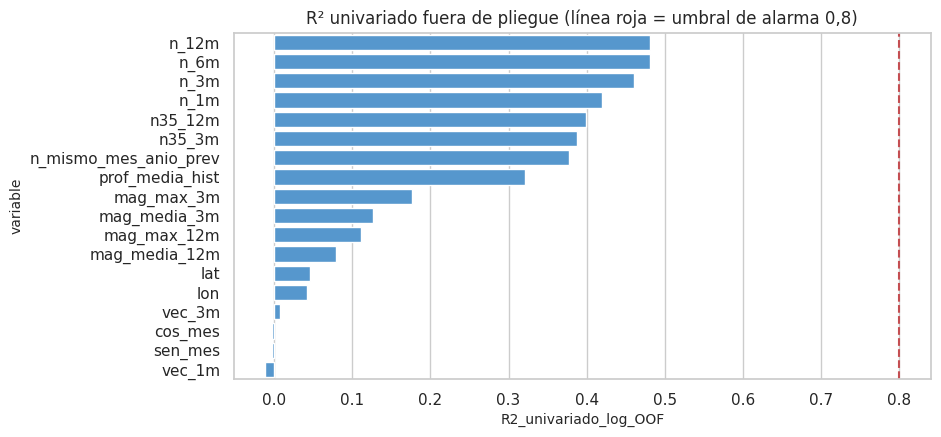

,variable,R2_univariado_log_OOF,corr_Pearson_log
3,n_12m,0.481,0.643
2,n_6m,0.481,0.646
1,n_3m,0.461,0.645
0,n_1m,0.420,0.634
5,n35_12m,0.399,0.625
4,n35_3m,0.387,0.612
13,n_mismo_mes_anio_prev,0.377,0.605
10,prof_media_hist,0.322,0.299
8,mag_max_3m,0.176,0.280
6,mag_media_3m,0.127,0.220


In [4]:
# Poder predictivo individual de cada variable (R² con un árbol en CV temporal): un R² sospechosamente alto delataría fuga
pl = datos.pliegues_temporales(tm[tr])
filas = []
for c in X.columns:
    x = X[c].to_numpy()[tr].reshape(-1, 1)
    x = np.where(np.isnan(x), -1, x)
    pred, obs = [], []
    for a, v in pl:
        m_ = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, random_state=cfg.SEMILLA).fit(x[a], ly[tr][a])
        pred.append(m_.predict(x[v])); obs.append(ly[tr][v])
    pred, obs = np.concatenate(pred), np.concatenate(obs)
    filas.append({"variable": c, "R2_univariado_log_OOF": r2_score(obs, pred),
                  "corr_Pearson_log": np.corrcoef(np.nan_to_num(X[c].to_numpy()[tr], nan=-1), ly[tr])[0, 1]})
uni = pd.DataFrame(filas).sort_values("R2_univariado_log_OOF", ascending=False)
eda.guardar_tabla(uni, "auditoria_univariado.csv")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=uni, y="variable", x="R2_univariado_log_OOF", color="#4299e1", ax=ax); ax.axvline(0.8, c="r", ls="--")
ax.set_title("R² univariado fuera de pliegue (línea roja = umbral de alarma 0,8)"); eda.guardar_figura(fig, "09_univariado.png"); plt.show()
uni.round(3)

In [5]:
md(f"""**Interpretación.**
- **Ninguna variable se acerca a la alarma.** El R² univariado más alto es {es(uni.R2_univariado_log_OOF.max(), 3)} (`{uni.variable.iloc[0]}`), lejos de 0,8. Es
  alto para una sola variable porque separa las celdas activas de las inactivas, pero no lo bastante para sugerir un proxy del objetivo.
- **No hay proxies del objetivo.** Ninguna variable lo «contiene». Todas son resúmenes del **pasado** de la celda o de su vecindad, y lo que
  aportan es el mismo tipo de información (persistencia), que el EDA ya mostró moderada.
- **Identificadores.** No se usa el número de celda como predictora. Latitud y longitud cumplen ese papel de forma continua y quedan
  **en observación**: son legítimas para pronosticar en las mismas celdas, pero inflarían el desempeño si se evaluara en zonas nuevas.
  Por eso la validación espacial del capítulo 11 se reporta aparte.""")

**Interpretación.**
- **Ninguna variable se acerca a la alarma.** El R² univariado más alto es 0,481 (`n_12m`), lejos de 0,8. Es
  alto para una sola variable porque separa las celdas activas de las inactivas, pero no lo bastante para sugerir un proxy del objetivo.
- **No hay proxies del objetivo.** Ninguna variable lo «contiene». Todas son resúmenes del **pasado** de la celda o de su vecindad, y lo que
  aportan es el mismo tipo de información (persistencia), que el EDA ya mostró moderada.
- **Identificadores.** No se usa el número de celda como predictora. Latitud y longitud cumplen ese papel de forma continua y quedan
  **en observación**: son legítimas para pronosticar en las mismas celdas, pero inflarían el desempeño si se evaluara en zonas nuevas.
  Por eso la validación espacial del capítulo 11 se reporta aparte.

## 9.3 Demostración: modelo **con fuga** frente a **sin fuga**

Para dimensionar el riesgo se construyen tres variables con fuga deliberada y se comparan con el modelo
sin fuga. Se usa una regresión Ridge sobre log(1 + y) con las 18 variables, entrenada con el
entrenamiento y evaluada en la prueba:

- **A. Fuga directa parcial:** sismos de la celda en la **primera semana** del mes objetivo.
- **B. Fuga por vecindad:** sismos de las 8 celdas vecinas **en el mes objetivo**.
- **C. Fuga por selección:** se eligen las celdas activas usando **todo** el periodo (incluida la
  prueba). Se mide cuántas celdas más entrarían.

In [6]:
# Experimento de fuga: agregar la primera semana del mes objetivo y medir cuánto «mejora» el modelo
semana1 = ev_[ev_.time.dt.day <= 7]
S1 = np.zeros_like(info["C"]); np.add.at(S1, (semana1.celda.to_numpy(), semana1.mes.to_numpy()), 1)
fuga_a = S1[info["cc"], info["tm"]]
fuga_b = datos.vecindad(info["C"], info["n_lat"], info["n_lon"])[info["cc"], info["tm"]]
def ridge_r2(extra=None):
    Z = X.copy()
    if extra is not None:
        Z["fuga"] = np.log1p(extra)
    m_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0)).fit(Z.iloc[tr], ly[tr])
    p = np.expm1(m_.predict(Z.iloc[te])).clip(0)
    met = ev.metricas_regresion(y[te], p)
    return met["RMSLE"], met["R2_log"], met["R2"]
filas = [("sin fuga (18 variables)", *ridge_r2()), ("A: + sismos de la 1.ª semana del mes objetivo", *ridge_r2(fuga_a)),
         ("B: + sismos vecinos del mes objetivo", *ridge_r2(fuga_b))]
demo = pd.DataFrame(filas, columns=["modelo", "RMSLE", "R² (log)", "R² (conteos)"])
celdas_todo = np.where(info["C"].sum(1) >= cfg.MIN_EVENTOS_CELDA)[0]
eda.guardar_tabla(demo, "con_fuga_vs_sin_fuga.csv")
display(demo.round(3))
md(f"""**Interpretación.**
- **Fuga directa (A).** Una semana del mes objetivo basta para bajar el RMSLE de {es(demo.RMSLE[0], 3)} a {es(demo.RMSLE[1], 3)} y subir el R² en log de
  {es(demo['R² (log)'][0], 2)} a {es(demo['R² (log)'][1], 2)}.
- **Fuga por vecindad (B).** La mejora es pequeña (R² log = {es(demo['R² (log)'][2], 2)}), porque la actividad de las vecinas en el mismo mes está
  poco correlacionada con la de la celda (capítulo 8). Aun así sería una mejora **falsa**.
- **Lectura.** Esas variables no existen al cierre del mes *t*. La fuga directa (A) dispara el desempeño de forma notoria con solo una semana de
  información. Que el modelo sin fuga quede lejos de esos valores es coherente con un diseño limpio.
- **Fuga por selección (C).** Si las celdas activas se eligieran con todo el periodo, entrarían **{len(celdas_todo) - len(info['celdas'])} celdas más**:
  celdas que solo se activaron después de 2020. El modelo se evaluaría justamente donde «sabemos» que va a haber sismos. Por eso el criterio
  usa solo los meses anteriores al corte.""")

,modelo,RMSLE,R² (log),R² (conteos)
0,sin fuga (18 variables),0.374,0.495,-6.615
1,A: + sismos de la 1.ª semana del mes objetivo,0.316,0.638,-0.703
2,B: + sismos vecinos del mes objetivo,0.370,0.505,-7.338


**Interpretación.**
- **Fuga directa (A).** Una semana del mes objetivo basta para bajar el RMSLE de 0,374 a 0,316 y subir el R² en log de
  0,49 a 0,64.
- **Fuga por vecindad (B).** La mejora es pequeña (R² log = 0,50), porque la actividad de las vecinas en el mismo mes está
  poco correlacionada con la de la celda (capítulo 8). Aun así sería una mejora **falsa**.
- **Lectura.** Esas variables no existen al cierre del mes *t*. La fuga directa (A) dispara el desempeño de forma notoria con solo una semana de
  información. Que el modelo sin fuga quede lejos de esos valores es coherente con un diseño limpio.
- **Fuga por selección (C).** Si las celdas activas se eligieran con todo el periodo, entrarían **24 celdas más**:
  celdas que solo se activaron después de 2020. El modelo se evaluaría justamente donde «sabemos» que va a haber sismos. Por eso el criterio
  usa solo los meses anteriores al corte.

## 9.4 Duplicados y entidades entre particiones; fuga temporal y espacial

In [7]:
# Chequeos de la partición: sin filas repetidas y prueba estrictamente posterior al entrenamiento
m_test = info["m_test"]
tm_tr_max, tm_te_min = int(tm[tr].max()), int(tm[te].min())
chequeo = pd.DataFrame([
    ("Filas (celda, mes objetivo) repetidas entre entrenamiento y prueba", int(len(set(zip(info['cc'][tr], tm[tr])) & set(zip(info['cc'][te], tm[te]))))),
    ("Último mes objetivo de entrenamiento", f"{datos.fecha_de_mes(tm_tr_max)[0]:%Y-%m}"),
    ("Primer mes objetivo de prueba", f"{datos.fecha_de_mes(tm_te_min)[0]:%Y-%m}"),
    ("Meses de separación (gap) entre objetivos", tm_te_min - tm_tr_max - 1),
    ("¿Algún sismo es objetivo en prueba y predictora o objetivo en entrenamiento?", "no" if (info['tt'][tr].max() < tm_te_min and tm_tr_max < tm_te_min) else "SÍ"),
    ("Mes más reciente usado por una variable de entrenamiento", f"{datos.fecha_de_mes(info['tt'][tr].max())[0]:%Y-%m}"),
    ("Celdas presentes en ambas particiones (entidades repetidas)", f"{len(set(info['cc'][tr]) & set(info['cc'][te]))} de {len(info['celdas'])} (por diseño)"),
    ("Rezago espacial: mes de los vecinos", "t (igual que la celda), nunca t+1"),
], columns=["chequeo", "resultado"])
eda.guardar_tabla(chequeo, "auditoria_particiones.csv")
chequeo

,chequeo,resultado
0,"Filas (celda, mes objetivo) repetidas entre en...",0
1,Último mes objetivo de entrenamiento,2020-11
2,Primer mes objetivo de prueba,2021-01
3,Meses de separación (gap) entre objetivos,1
4,¿Algún sismo es objetivo en prueba y predictor...,no
5,Mes más reciente usado por una variable de ent...,2020-10
6,Celdas presentes en ambas particiones (entidad...,163 de 163 (por diseño)
7,Rezago espacial: mes de los vecinos,"t (igual que la celda), nunca t+1"


In [8]:
md("""**Interpretación.**
- **Particiones disjuntas.** No hay filas repetidas entre entrenamiento y prueba, y ningún sismo que sea objetivo de la prueba aparece en el
  entrenamiento, ni como objetivo ni como predictora.
- **Entidades repetidas por diseño.** Las mismas celdas aparecen en ambas particiones. No es fuga: el problema es pronosticar el **futuro** de
  zonas conocidas, igual que un pronóstico del tiempo usa las mismas estaciones. Lo que no puede compartirse es **tiempo**, y la partición
  cronológica con gap lo garantiza.
- **Uso legítimo del pasado.** Las variables de la prueba sí usan sismos de 2020, que en el entrenamiento fueron objetivo. Eso es legítimo:
  al pronosticar enero de 2021, los sismos de 2020 ya ocurrieron y se conocen.
- **Fuga espacial.** El rezago espacial usa los vecinos en el mismo mes *t* que la celda, así que no introduce información del mes objetivo.
  La variante con fuga (B) se descartó.""")

**Interpretación.**
- **Particiones disjuntas.** No hay filas repetidas entre entrenamiento y prueba, y ningún sismo que sea objetivo de la prueba aparece en el
  entrenamiento, ni como objetivo ni como predictora.
- **Entidades repetidas por diseño.** Las mismas celdas aparecen en ambas particiones. No es fuga: el problema es pronosticar el **futuro** de
  zonas conocidas, igual que un pronóstico del tiempo usa las mismas estaciones. Lo que no puede compartirse es **tiempo**, y la partición
  cronológica con gap lo garantiza.
- **Uso legítimo del pasado.** Las variables de la prueba sí usan sismos de 2020, que en el entrenamiento fueron objetivo. Eso es legítimo:
  al pronosticar enero de 2021, los sismos de 2020 ya ocurrieron y se conocen.
- **Fuga espacial.** El rezago espacial usa los vecinos en el mismo mes *t* que la celda, así que no introduce información del mes objetivo.
  La variante con fuga (B) se descartó.

## 9.5 Fuga por preprocesamiento

- **Qué se aprende de los datos y con qué se ajusta.** La imputación (medianas), el escalado (medias y
  desviaciones), la transformación y los hiperparámetros se aprenden **dentro de un `Pipeline`** que se
  ajusta solo con el entrenamiento, o solo con la parte de ajuste de cada pliegue.
- **Comprobación.** Se ajusta el Pipeline con el entrenamiento y se verifica que sus parámetros
  coinciden con estadísticos calculados solo con entrenamiento y no con todo el panel.

In [9]:
# El preprocesamiento usa solo estadísticas del entrenamiento (mediana, media del escalador)
pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X.iloc[tr])
med_tr = X.iloc[tr].median().to_numpy()
med_todo = X.median().to_numpy()
media_tr = X.iloc[tr].fillna(X.iloc[tr].median()).mean().to_numpy()
pp = pd.DataFrame({"variable": X.columns, "mediana_imputador": pipe[0].statistics_, "mediana_train": med_tr, "mediana_todo": med_todo,
                   "media_escalador": pipe[1].mean_, "media_train": media_tr})
ok = np.allclose(pp.mediana_imputador, pp.mediana_train) and np.allclose(pp.media_escalador, pp.media_train)
eda.guardar_tabla(pp, "auditoria_preprocesamiento.csv")
md(f"""Los parámetros del Pipeline **{'coinciden' if ok else 'NO coinciden'}** con los estadísticos de entrenamiento. En
{int((~np.isclose(pp.mediana_train, pp.mediana_todo)).sum())} variables la mediana de todo el panel difiere de la del entrenamiento: si se hubiera ajustado con todo,
habría habido fuga. Otras decisiones aprendidas de los datos:
- la normalización de las variables de excitación (Entregable 2) usa solo meses anteriores al corte (`src/datos.py::ExcitacionMensual.energia`);
- la selección de celdas activas usa solo meses anteriores al corte (sección 9.3).""")
pp[pp.variable.isin(["n_12m", "vec_3m", "mag_media_3m", "prof_media_hist"])].round(3)

Los parámetros del Pipeline **coinciden** con los estadísticos de entrenamiento. En
4 variables la mediana de todo el panel difiere de la del entrenamiento: si se hubiera ajustado con todo,
habría habido fuga. Otras decisiones aprendidas de los datos:
- la normalización de las variables de excitación (Entregable 2) usa solo meses anteriores al corte (`src/datos.py::ExcitacionMensual.energia`);
- la selección de celdas activas usa solo meses anteriores al corte (sección 9.3).

,variable,mediana_imputador,mediana_train,mediana_todo,media_escalador,media_train
3,n_12m,3.000,3.000,2.000,9.896,9.896
6,mag_media_3m,2.843,2.843,2.833,2.882,2.882
10,prof_media_hist,27.827,27.827,27.776,38.442,38.442
12,vec_3m,5.000,5.000,5.000,17.484,17.484


## 9.6 Conclusión de la auditoría

| Variable o decisión | Estado | Justificación |
|---|---|---|
| 18 predictoras del modelo base | **conservadas** | Disponibles al cierre de *t*; R² univariado ≤ 0,5 (lejos de la alarma de 0,8); sin proxies del objetivo |
| `lat`, `lon` | **en observación** | Válidas para pronosticar en las mismas celdas; se reporta aparte la validación espacial |
| `prof_media_hist` | **en observación** | Acumulativa: es la que más deriva (cap. 7), pero sin fuga |
| sismos del mes objetivo (cualquier resumen) | **descartadas** | Fuga directa (demostración A) |
| sismos vecinos del mes objetivo | **descartadas** | Fuga espacio-temporal (demostración B) |
| `depto`, errores de localización, estado | **descartadas como predictoras** | No aportan al pronóstico o no están a tiempo |
| celdas activas y normalizaciones | **calculadas solo con entrenamiento** | Evita la fuga por selección (C) y por preprocesamiento |

**Veredicto.** La auditoría está **limpia**. El desempeño que se reporte desde el capítulo 11 es una
estimación honesta del pronóstico real.